# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

He 2021's metastatic-prostate malignant manifold is **non-branching**: the developmental signatures
collapse onto a **single dominant axis** — a Gastrulation/posterior-somitogenesis-high origin opposed
to a neural-crest (Crest) terminus — rather than a hub radiating into two arms with Gast↔pSom
cross-repression. On the smoothed manifold Crest strongly opposes both Gast (r≈−0.82) and pSom
(r≈−0.70), while Gast↔pSom is weakly **positive** (r≈+0.18) — the opposite of the negative
cross-repression axis a bifurcation requires. The correct topology is therefore a **principal curve**
(ElPiGraph, non-branching by construction) fit on the *joint* embedding — **not** a re-embedding.

**Scope decision (derived, not inherited).** The three Leiden lobes carry the *same* developmental
gradient (the Gast/pSom→Crest axis runs across all of them; per-lobe means differ smoothly, not as
separate territories), and the neural-crest terminus is genuinely terminal rather than a proliferation
artifact — Crest correlates with cell-cycle score at ρ≈0.00 (Gast ρ≈−0.31 at the low-cycling origin,
as expected). So, unlike Kürten 2021 (which excluded a cycling lobe), there is **no proliferation lobe
to exclude**: the whole manifold is the honest developmental object (Bischoff/Sun/Lee no-scoping
precedent). The curve is rooted at the Gast/pSom-high tip and pseudotime flows to the neural-crest
terminus. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Keep all cells on their *original joint embedding coordinates* — no re-embedding. The three embryonic
signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against the shared **union**
control pool and graph-smoothed to read geography rather than SmartSeq2 per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
c = xy - xy.mean(0); u,s,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 833 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 2.73
Gast: 69/81 genes present
pSom: 76/98 genes present
Crest: 91/104 genes present
raw module means (honest readout): {'Gast': -0.3019, 'pSom': 0.0547, 'Crest': 0.0459}


### Scope decision — whole manifold vs one lobe (data-driven)
Test whether the developmental axis is confined to one lobe (Kürten case, scoping justified) or spans
all (Bischoff/Sun/Lee case, whole manifold kept). Three facts settle it for He prostate: (i) the
smoothed signatures form **one** axis (Crest opposite Gast and pSom; Gast↔pSom weakly positive, not a
cross-repression hub); (ii) the Crest-high terminus is spread across the lobes as the end of a shared
gradient, not a separate developmental territory; (iii) cell-cycle score correlates **negligibly** with
every module (|ρ|≤0.31, Crest ρ≈0.00), so proliferation is not a confound of the axis and there is no
cycling lobe to exclude. Keep the whole manifold.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-lobe smoothed developmental means:')
print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
frac = adata.obs.loc[hi.values,'lobe'].value_counts(normalize=True).round(2).to_dict()
print('\nCrest-high decile distribution across lobes:', frac)
cyc = np.maximum(adata.obs['g1s_score'].values, adata.obs['g2m_score'].values)
for m in ['Gast','pSom','Crest']:
    rho,_ = spearmanr(cyc, adata.obs[m].values); print(f'  {m} vs cycling score: rho = {rho:+.2f}')
print('-> developmental axis is orthogonal to proliferation; keep whole manifold (no scoping).')
sub = adata

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.18
  Crest_sm vs Gast_sm: r = -0.82
  Crest_sm vs pSom_sm: r = -0.70

per-lobe smoothed developmental means:
      Gast_sm  pSom_sm  Crest_sm
lobe                            
0     -0.1622   0.0778   -0.0259
1     -0.2937   0.0898    0.0154
2     -0.4099   0.0291    0.1160

Crest-high decile distribution across lobes: {'2': 1.0, '0': 0.0, '1': 0.0}
  Gast vs cycling score: rho = -0.31
  pSom vs cycling score: rho = +0.12
  Crest vs cycling score: rho = -0.00
-> developmental axis is orthogonal to proliferation; keep whole manifold (no scoping).


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` are derived for *this* manifold (833 cells) — not inherited from the Puram
PPT settings. A node self-approach ratio > 1 (minimum distance between graph-non-adjacent nodes, in
units of median edge length) certifies the curve does not fold back on itself; `forks==0` confirms
non-branching. We sweep four (Nodes, λ, μ) combinations to show the topology (2 tips, 0 forks,
fold-free) is robust, then commit the smoothest fold-free fit.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
print('curve topology sweep (Nodes, epg_lambda, epg_mu):')
for Nodes,lam,mu in [(20,0.3,100.0),(30,0.3,100.0),(15,0.5,100.0),(20,0.5,50.0)]:
    tmp = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(tmp, Nodes=Nodes, use_rep='X_umap', epg_lambda=lam, epg_mu=mu, seed=SEED, plot=False)
    sa,tips,forks = fold_diag(tmp)
    print(f'  Nodes={Nodes} lambda={lam} mu={mu}: tips={tips} forks={forks} self-approach={sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'committed curve (Nodes=20, lambda=0.3, mu=100): {tips} tips, {forks} forks | '
      f'fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve topology sweep (Nodes, epg_lambda, epg_mu):
  Nodes=20 lambda=0.3 mu=100.0: tips=2 forks=0 self-approach=2.99
  Nodes=30 lambda=0.3 mu=100.0: tips=2 forks=0 self-approach=2.94
  Nodes=15 lambda=0.5 mu=100.0: tips=2 forks=0 self-approach=2.99
  Nodes=20 lambda=0.5 mu=50.0: tips=2 forks=0 self-approach=2.99
committed curve (Nodes=20, lambda=0.3, mu=100): 2 tips, 0 forks | fold self-approach ratio = 2.99 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin. Root
from the signatures' **developmental order** (Gast/pSom early, Crest LATE) — never at the Crest tip or a
proliferation state (the Kürten root fork). Pseudotime then flows to the neural-crest terminus.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')

tip 0: Gast=-0.1567 pSom=+0.0784 Crest=-0.0275
tip 2: Gast=-0.4203 pSom=+0.0468 Crest=+0.1133
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.991 p=0.0e+00
  pSom_sm: rho=-0.055 p=1.1e-01
  Crest_sm: rho=+0.853 p=3.0e-237
Neural-crest-high decile mean pseudotime = 0.91
Somitogenesis-high decile mean pseudotime = 0.68
Gastrulation-high decile mean pseudotime = 0.00


### House orientation (re-used from 01, verified against pseudotime)
The house orientation — a single rigid rotation of the diagonal developmental axis to horizontal — was
derived **once in 01** (rotation angle from the axis of maximal variance; sign from the
developmental-module geography, Gast/pSom-high origin on the left) and stored as `X_umap_lin`. Every UMAP
deliverable across 01–04 re-uses these exact coordinates, so orientation is consistent by construction
(binding). Here we **verify** it now that pseudotime exists: the stored `X_umap_lin` x-axis must correlate
strongly and positively with pseudotime (origin on the left).

In [7]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
c = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_, _, vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
print(f'variance-axis vs pseudotime-axis disagreement = {dang:.1f}deg (small -> equivalent orientation)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.99
variance-axis vs pseudotime-axis disagreement = 1.0deg (small -> equivalent orientation)


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


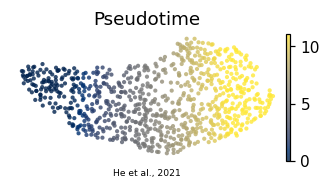

In [8]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'He et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')